# LAB 5 - TASK 1 submission. AI course. MU AICE 2026-27.

FILL UP THIS BOX WITH YOUR DETAILS

**NAME AND NIP**: Jorge Ruiz (826685) - Hugo López (875455)


# Building a GPT from Scratch: An Educational Notebook

This notebook builds a small **decoder-only Transformer language model** (the same architecture family as GPT-2/GPT-3) in plain PyTorch and trains it to generate Shakespeare-like text. It follows the structure of Andrej Karpathy's *"Let's build GPT: from scratch, in code, spelled out"* lecture ([video](https://www.youtube.com/watch?v=kCc8FmEb1nY)) and his [nanoGPT](https://github.com/karpathy/nanoGPT) repository.

❗❗❗❗❗**PREVIOUS WORK to the session**❗❗❗❗❗
1. **Read and Run** the COLAB (it can take 30-40 minutes if you can't use a GPU). Understand the different parts (review the transformer materials) and come to the lab with the colab cell outputs computed and saved.

**Learning objectives.** After working through the notebook you should be able to:

1. Explain what *autoregressive language modelling* is and how it is trained (next-token prediction with cross-entropy).
2. Implement character-level tokenization and batch construction for a language model.
3. Explain why *masked self-attention* is a weighted average over past tokens.
4. Implement queries, keys and values, scaled dot-product attention, multi-head attention, feed-forward blocks, residual connections and layer normalization.
5. Train a Transformer, monitor train/validation loss, and sample from it with temperature and top-k.
6. Inspect what individual attention heads learn.

**How to run.** If you run the notebook **on CPU** make sure you leave the default **FAST** preset in the CONFIGURATION section. If you can use your local GPU or Colab GPU runtime, you can try the FULL preset.

| Section | Topic |
|---|---|
| 0-2 | Setup, data, tokenization, batching |
| 3 | Baseline: bigram language model |
| 4 | The maths of self-attention |
| 5 | Assembling the Transformer |
| 6-8 | Training, sampling, attention maps |
| 9-10 | Exercises and where to go next |

## 0. Setup

In [1]:
import math
import os
import time
import urllib.request

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
#device = 'cuda' if torch.cuda.is_available() else 'cpu'
device = (
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(f"PyTorch {torch.__version__} | device: {device}")
if device == 'cpu':
    print("Tip: Runtime -> Change runtime type -> T4 GPU for a much faster full-size model.")

PyTorch 2.11.0+cu130 | device: cuda


## 1. Data and tokenization

We use the **Tiny Shakespeare** corpus (~1 MB of text, ~1.1M characters). It is small enough to train on in minutes but rich enough that the model learns recognisable structure: speaker names, line breaks, verse-like rhythm, archaic vocabulary.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
urllib.request.urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(f"Corpus length: {len(text):,} characters\n")
print(text[:400])

Corpus length: 1,115,394 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


### Tokenizer

A language model operates on integers, not strings. The simplest possible tokenizer is **character-level**: every distinct character is one token. Our vocabulary is tiny (~65 symbols), so the embedding table and output layer stay small, but sequences are long.

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
print("Vocabulary:", ''.join(chars).replace('\n', '\\n'))
print("Vocabulary size:", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}   # string -> int
itos = {i: ch for ch, i in stoi.items()}       # int -> string
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join(itos[i] for i in ids)

print(encode("First Citizen"))
print(decode(encode("First Citizen")))

Vocabulary: \n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
Vocabulary size: 65
[18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52]
First Citizen


In [4]:
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)

# 90% train / 10% validation. We split chronologically (no shuffling) so the
# validation text is genuinely unseen.
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"train tokens: {len(train_data):,} | val tokens: {len(val_data):,}")

torch.Size([1115394]) torch.int64
train tokens: 1,003,854 | val tokens: 111,540


## 2. CONFIGURATION: Hyperparameters and batching

Two presets are provided. `full` reproduces the lecture's model (~10.7M parameters) and is meant for a GPU; `fast` is a smaller model that still learns sensible text on CPU in a few minutes. Change `PRESET` to override the automatic choice.

| Hyperparameter | Meaning |
|---|---|
| `block_size` | Context length: how many previous tokens the model can see |
| `batch_size` | Independent sequences processed in parallel |
| `n_embd` | Width of the residual stream (embedding dimension) |
| `n_head` | Number of attention heads per block (`head_size = n_embd // n_head`) |
| `n_layer` | Number of Transformer blocks |
| `dropout` | Regularisation; important because the dataset is tiny |

In [5]:
PRESET = "full" if device == "cuda" else "fast"   # override with "fast" or "full"
# PRESET = "fast" if device == "cpu" else "full"   # run full with mps or cpu
# PRESET = "fast"

configs = {
    "fast": dict(batch_size=32, block_size=128, n_embd=128, n_head=4, n_layer=4,
                 dropout=0.1, learning_rate=1e-3, max_iters=3000, eval_interval=500),
    "full": dict(batch_size=64, block_size=256, n_embd=384, n_head=6, n_layer=6,
                 dropout=0.2, learning_rate=3e-4, max_iters=5000, eval_interval=500),
}
cfg = configs[PRESET]

batch_size    = cfg["batch_size"]
block_size    = cfg["block_size"]
n_embd        = cfg["n_embd"]
n_head        = cfg["n_head"]
n_layer       = cfg["n_layer"]
dropout       = cfg["dropout"]
learning_rate = cfg["learning_rate"]
max_iters     = cfg["max_iters"]
eval_interval = cfg["eval_interval"]
eval_iters    = 100

print(f"Preset '{PRESET}':", cfg)

Preset 'full': {'batch_size': 64, 'block_size': 256, 'n_embd': 384, 'n_head': 6, 'n_layer': 6, 'dropout': 0.2, 'learning_rate': 0.0003, 'max_iters': 5000, 'eval_interval': 500}


### How training examples are built

A single chunk of `block_size + 1` characters contains `block_size` training examples at once. For the chunk `"First Ci"` the model must learn:

| context (input) | target (next char) |
|---|---|
| `F` | `i` |
| `Fi` | `r` |
| `Fir` | `s` |
| ... | ... |

The targets `y` are simply the inputs `x` shifted by one position. Training on *all* context lengths from 1 to `block_size` is what lets the model generate from a very short prompt and also use a long one.

In [6]:
def get_batch(split):
    """Sample a random batch of (input, target) sequences."""
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print("inputs :", xb.shape, "\ntargets:", yb.shape)

print("\nThe first sequence of the batch, unrolled into its training examples:")
for t in range(8):
    context = xb[0, :t + 1].tolist()
    target = yb[0, t].item()
    print(f"  context {decode(context)!r:>12}  ->  target {decode([target])!r}")

inputs : torch.Size([64, 256]) 
targets: torch.Size([64, 256])

The first sequence of the batch, unrolled into its training examples:
  context         '\n'  ->  target 'N'
  context        '\nN'  ->  target 'o'
  context       '\nNo'  ->  target 't'
  context      '\nNot'  ->  target ' '
  context     '\nNot '  ->  target 'G'
  context    '\nNot G'  ->  target 'l'
  context   '\nNot Gl'  ->  target 'o'
  context  '\nNot Glo'  ->  target 'u'


## 3. Shared utilities and a baseline: the bigram model

Before building a Transformer, we define three helpers used by *every* model in this notebook:

* `estimate_loss`: average loss over many random batches (a single batch is too noisy to trust),
* `train`: a standard training loop with AdamW,
* `generate`: autoregressive sampling, with optional `temperature` and `top_k`.

**Autoregressive generation** repeats three steps: (1) feed the current context to the model, (2) take the logits for the *last* position and turn them into a probability distribution with softmax, (3) sample a token from it, append it, and go again. The context is cropped to the last `block_size` tokens because the position embedding table only has that many rows.

In [7]:
@torch.no_grad()
def estimate_loss(model, iters=eval_iters):
    model.eval()
    out = {}
    for split in ['train', 'val']:
        losses = torch.zeros(iters)
        for k in range(iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def train(model, max_iters, lr, eval_interval=500,
          save_checkpoints=False, checkpoint_dir="checkpoints"):
    """Train with AdamW; optionally save validation-step and best checkpoints."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    best_val_loss = float('inf')
    best_state = None
    run_id = time.strftime("%Y%m%d-%H%M%S")
    if save_checkpoints:
        os.makedirs(checkpoint_dir, exist_ok=True)
    model.train()
    t0 = time.time()
    for it in range(max_iters + 1):
        if it % eval_interval == 0:
            losses = estimate_loss(model)
            history.append((it, losses['train'], losses['val']))
            print(f"step {it:5d} | train loss {losses['train']:.4f} | "
                  f"val loss {losses['val']:.4f} | {time.time() - t0:6.1f}s")
            if save_checkpoints:
                checkpoint_path = os.path.join(
                    checkpoint_dir,
                    f"checkpoint_{run_id}_step_{it:06d}_val_{losses['val']:.4f}.pt",
                )
                torch.save(model.state_dict(), checkpoint_path)
            if losses['val'] < best_val_loss:
                best_val_loss = losses['val']
                best_state = {
                    name: value.detach().clone()
                    for name, value in model.state_dict().items()
                }
                if save_checkpoints:
                    best_path = os.path.join(checkpoint_dir, f"best_{run_id}.pt")
                    torch.save(best_state, best_path)
        if it == max_iters:
            break
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    if best_state is not None:
        model.load_state_dict(best_state)
    return history


@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, top_k=None):
    """Autoregressively extend `idx` (shape (B, T)) by max_new_tokens tokens."""
    model.eval()
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]                 # crop to the context window
        logits, _ = model(idx_cond)                     # (B, T, vocab)
        logits = logits[:, -1, :] / temperature         # last position only
        if top_k is not None:                           # keep only the k best tokens
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float('inf')
        probs = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

### The bigram model

The simplest possible language model predicts the next character **using only the current character**: a lookup table of size `vocab_size x vocab_size` whose rows are the logits for the next token. It has no notion of context, which makes it the perfect baseline.

**Sanity check:** with a uniform prediction over 65 characters the loss should be $-\ln(1/65) \approx 4.17$. The bigram model's default random initialisation starts a bit higher (around 4.5-5), because its logits are not small; the Transformer below uses small weights and starts almost exactly at 4.17. A loss *far* above or below this value means something is wrong (initialisation, loss computation, ...). This check is worth doing for every new model you build.

In [8]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # Each token directly reads off the logits of the next token.
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)            # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


bigram = BigramLanguageModel(vocab_size).to(device)
xb, yb = get_batch('train')
_, loss = bigram(xb, yb)
print(f"Initial loss: {loss.item():.3f}   (uniform guess = {math.log(vocab_size):.3f})")

start = torch.zeros((1, 1), dtype=torch.long, device=device)   # token 0 is '\n'
print("\n--- untrained bigram sample ---")
print(decode(generate(bigram, start, 200)[0].tolist()))

Initial loss: 4.766   (uniform guess = 4.174)

--- untrained bigram sample ---

DYCz$bMkRZk
gc'wb,ZT,O-zsScbtK
ga!POz'TBFzou3:BaSGBO-3DSMBk?YLhaUhX:LVXJtDINNuwqhPM$v.t?V;ddX3rFHaAeNFw3yMwmRWfnjDsZaYzyzoINmX
Y
w&$
MtofViyzvB!!&V!Ox;FdilK!,ue3:ivYeY?YBkciK;laP;HmlcdE&GDEcSXHBLqWkn-


In [9]:
bigram_history = train(bigram, max_iters=3000, lr=1e-2, eval_interval=500)

print("\n--- trained bigram sample ---")
print(decode(generate(bigram, start, 300)[0].tolist()))

step     0 | train loss 4.7529 | val loss 4.7573 |    0.4s
step   500 | train loss 2.5172 | val loss 2.5432 |    2.4s
step  1000 | train loss 2.4740 | val loss 2.4980 |    4.3s
step  1500 | train loss 2.4639 | val loss 2.4895 |    6.1s
step  2000 | train loss 2.4594 | val loss 2.4888 |    7.9s
step  2500 | train loss 2.4565 | val loss 2.4854 |    9.7s
step  3000 | train loss 2.4561 | val loss 2.4842 |   11.6s

--- trained bigram sample ---

BE:
Wileranousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Herindu n Boopetelaves
MP:

Pl, d mothakleo Windo whthCoribyo the m dourive we hidend t so mower; te

AN ad nterupt f s ar iris! m:

Thiny aleronth,
Mad
RD:

WISo myr f-
LIERor,
SShisar adsal thes ghesthidin cour ay aney Iry ts I fr y ce.
J


The bigram model learns letter frequencies and which letters tend to follow which (it quickly stops producing pure noise), but it cannot form words reliably, because it never looks further back than one character. To do better, tokens need to **communicate** with earlier tokens. That is what self-attention provides.

## 4. Self-attention: queries, keys and values

Averaging all past tokens treats them as equally interesting. Self-attention lets each token **decide** which past tokens matter, depending on content. Every token emits three vectors:

* a **query** $q$: *"what am I looking for?"*
* a **key** $k$: *"what do I contain?"*
* a **value** $v$: *"if you attend to me, this is what I will communicate."*

The affinity between token $i$ and token $j$ is the dot product $q_i \cdot k_j$. After masking the future and applying softmax, these affinities become the averaging weights, and the output is the weighted sum of the values:

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

where $M$ is the causal mask ($0$ on and below the diagonal, $-\infty$ above).

Some key properties to remember: attention has **no built-in notion of order** (hence the position embeddings later); there is **no communication across the batch dimension**; and an encoder-style block would simply drop the mask (here we keep it, which makes this a *decoder* block).

In [10]:
torch.manual_seed(1337)
B, T, C = 4, 8, 32           # batch, time, channels
head_size = 16
x = torch.randn(B, T, C)

key   = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k, q, v = key(x), query(x), value(x)                    # each (B, T, head_size)
wei = q @ k.transpose(-2, -1) * head_size ** -0.5       # (B, T, T) scaled affinities

tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))         # causal mask
wei = F.softmax(wei, dim=-1)                            # rows sum to 1
out = wei @ v                                           # (B, T, head_size)

print("output shape:", out.shape)
print("rows sum to 1:", torch.allclose(wei.sum(-1), torch.ones(B, T)))
print("\nAttention weights of the first sequence (rows = queries, cols = keys):")
print(wei[0].detach().numpy().round(2))

output shape: torch.Size([4, 8, 16])
rows sum to 1: True

Attention weights of the first sequence (rows = queries, cols = keys):
[[1.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.4  0.6  0.   0.   0.   0.   0.   0.  ]
 [0.31 0.29 0.4  0.   0.   0.   0.   0.  ]
 [0.32 0.22 0.24 0.21 0.   0.   0.   0.  ]
 [0.15 0.2  0.17 0.15 0.34 0.   0.   0.  ]
 [0.13 0.25 0.13 0.11 0.31 0.07 0.   0.  ]
 [0.16 0.2  0.11 0.11 0.14 0.17 0.11 0.  ]
 [0.08 0.12 0.11 0.15 0.11 0.11 0.16 0.16]]


### Why divide by $\sqrt{d_k}$?

If $q$ and $k$ have unit variance, then $q\cdot k$ has variance $\approx d_k$. Large-magnitude scores push softmax towards a **one-hot** distribution, so each token would attend to a single other token, **and gradients through the softmax become tiny** (*vanish*). Scaling by $1/\sqrt{d_k}$ keeps the scores at unit variance and the softmax diffuse at initialisation.

In [11]:
torch.manual_seed(0)
d = 64
q_ = torch.randn(1000, 8, d)
k_ = torch.randn(1000, 8, d)
raw = q_ @ k_.transpose(-2, -1)
print(f"variance of q.k without scaling: {raw.var().item():6.1f}   (head_size = {d})")
print(f"variance of q.k with 1/sqrt(d):  {(raw * d ** -0.5).var().item():6.1f}")

scores = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print("\nsoftmax when lower variance (small scores) :", F.softmax(scores, dim=0).numpy().round(3))
print("softmax when high variance (scores x 8) :", F.softmax(scores * 8, dim=0).numpy().round(3), " <- sharpens towards one-hot")

variance of q.k without scaling:   63.6   (head_size = 64)
variance of q.k with 1/sqrt(d):     1.0

softmax when lower variance (small scores) : [0.192 0.143 0.235 0.143 0.287]
softmax when high variance (scores x 8) : [0.033 0.003 0.162 0.003 0.8  ]  <- sharpens towards one-hot


## 5. Assembling the Transformer

We now build the complete model bottom-up. The overall data flow for one forward pass is:

```
token ids (B,T)
   -> token embedding + position embedding        (B,T,n_embd)
   -> N x [ x = x + MultiHeadSelfAttention(LayerNorm(x))
            x = x + FeedForward(LayerNorm(x)) ]   (B,T,n_embd)
   -> LayerNorm -> Linear(n_embd, vocab_size)     (B,T,vocab_size) = logits
```

Design choices worth discussing:

* **Multi-head attention** runs several smaller attention heads in parallel (each with `head_size = n_embd // n_head`) and concatenates them. Different heads can specialise in different relationships, at the same total cost as one big head.
* **Feed-forward network** (two linear layers with a non-linearity and 4x expansion) is applied to each position independently: attention is *communication*, the MLP is *computation*.
* **Residual connections** give gradients a direct path through the network and make deep stacks trainable.
* **Layer normalization** stabilises activations. We use the **pre-norm** variant (norm *before* attention/MLP), which is what GPT-2 and most modern LLMs use; the original Transformer paper used post-norm.
* **Dropout** after attention weights, after projections and after the MLP fights over-fitting on this small dataset.

Hyperparameters (`n_embd`, `block_size`, `dropout`, ...) are read from the globals defined in Section 2 to keep the code compact.

In [12]:
class Head(nn.Module):
    """One head of causal self-attention."""

    def __init__(self, head_size):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # 'tril' is not a parameter; register_buffer stores it with the module
        # (moves with .to(device), saved in state_dict) but is not trained.
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
        self.keep_attn = False        # set True to store attention maps for visualisation
        self.last_wei = None

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                              # (B, T, hs)
        q = self.query(x)                                            # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5          # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # causal mask
        wei = F.softmax(wei, dim=-1)
        if self.keep_attn:
            self.last_wei = wei.detach().cpu()
        wei = self.dropout(wei)
        v = self.value(x)                                            # (B, T, hs)
        return wei @ v                                               # (B, T, hs)


class MultiHeadAttention(nn.Module):
    """Several attention heads in parallel, concatenated and projected back."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)          # (B, T, n_embd)
        return self.dropout(self.proj(out))

In [13]:
class FeedForward(nn.Module):
    """Position-wise MLP: Linear -> ReLU -> Linear, with a 4x hidden expansion."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Transformer block: communication (attention) followed by computation (MLP)."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))      # residual connection around attention
        x = x + self.ffwd(self.ln2(x))    # residual connection around MLP
        return x

In [14]:
class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)               # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)   # hidden state -> logits
        self.apply(self._init_weights)

    def _init_weights(self, module):
        # Small initial weights -> near-uniform initial predictions -> initial loss ~ ln(vocab_size)
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                   # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device)) # (T, n_embd)
        x = tok_emb + pos_emb                                                       # position info added
        x = self.blocks(x)                                                          # (B, T, n_embd)
        x = self.ln_f(x)
        logits = self.lm_head(x)                                                    # (B, T, vocab_size)

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

## 6. Training

Instantiate the model, verify the initial loss, and train. On a Colab T4 the `full` preset takes roughly 15-20 minutes; the `fast` preset a few minutes.

In [15]:
torch.manual_seed(1337)           # re-seed: Sections 4-5 consumed random numbers
model = GPTLanguageModel().to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params / 1e6:.2f}M parameters")

xb, yb = get_batch('train')
_, loss = model(xb, yb)
print(f"Initial loss: {loss.item():.3f}   (uniform guess = {math.log(vocab_size):.3f})")

10.79M parameters
Initial loss: 4.222   (uniform guess = 4.174)


In [16]:
history = train(
    model,
    max_iters=max_iters,
    lr=learning_rate,
    eval_interval=eval_interval,
    save_checkpoints=True,
    checkpoint_dir="checkpoints",
)

step     0 | train loss 4.2216 | val loss 4.2311 |   34.7s
step   500 | train loss 1.7446 | val loss 1.9007 |  355.9s
step  1000 | train loss 1.3883 | val loss 1.6074 |  674.3s
step  1500 | train loss 1.2673 | val loss 1.5368 |  992.8s
step  2000 | train loss 1.1873 | val loss 1.5048 | 1310.5s
step  2500 | train loss 1.1212 | val loss 1.4885 | 1628.0s
step  3000 | train loss 1.0648 | val loss 1.4893 | 1945.8s
step  3500 | train loss 1.0155 | val loss 1.5032 | 2262.8s
step  4000 | train loss 0.9558 | val loss 1.5168 | 2578.2s
step  4500 | train loss 0.9058 | val loss 1.5503 | 2892.6s
step  5000 | train loss 0.8510 | val loss 1.5694 | 3208.5s


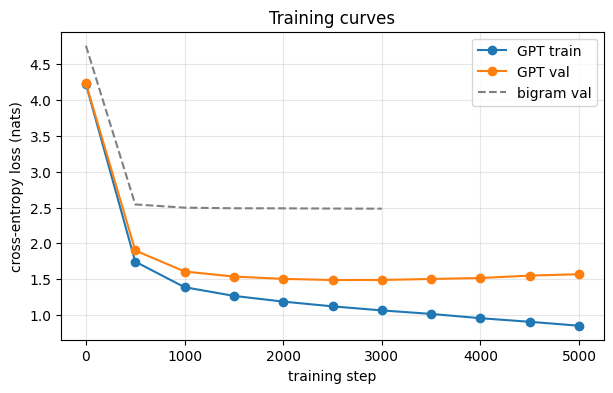

Final validation loss -> bigram: 2.484 | GPT: 1.569
Perplexity (exp of loss) -> bigram: 12.0 | GPT: 4.8


In [17]:
its, tr, va = zip(*history)
plt.figure(figsize=(7, 4))
plt.plot(its, tr, marker='o', label='GPT train')
plt.plot(its, va, marker='o', label='GPT val')
b_its, _, b_va = zip(*bigram_history)
plt.plot(b_its, b_va, linestyle='--', color='gray', label='bigram val')
plt.xlabel('training step'); plt.ylabel('cross-entropy loss (nats)')
plt.title('Training curves'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"Final validation loss -> bigram: {bigram_history[-1][2]:.3f} | GPT: {history[-1][2]:.3f}")
print(f"Perplexity (exp of loss) -> bigram: {math.exp(bigram_history[-1][2]):.1f} | GPT: {math.exp(history[-1][2]):.1f}")

### Saving and reloading the model.

In [18]:
# Checkpoints of the model are already stored during training. Sample code to save and load a model.

# torch.save(model.state_dict(), "gpt_shakespeare.pt")

# To reload later (the hyperparameters must match those used for training):
# model = GPTLanguageModel().to(device)
# model.load_state_dict(torch.load("gpt_shakespeare.pt", map_location=device))

# In Colab you can download the file with:
# from google.colab import files; files.download("gpt_shakespeare.pt")

## 7. Generating text

Start from a single newline token (index 0) and let the model write. Note that the model has learned structure only from next-character prediction: speaker tags, line lengths and many real words appear, but there is no understanding of meaning, so the text is locally plausible and globally incoherent.

**Sampling controls**

* **Temperature** rescales logits before softmax: $<1$ sharpens the distribution (safer, more repetitive), $>1$ flattens it (more diverse, more errors).
* **Top-k** restricts sampling to the $k$ most likely tokens, cutting off the long tail of unlikely characters.

In [19]:
torch.manual_seed(0)
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(generate(model, start, max_new_tokens=600)[0].tolist()))


As I hear easy the impossible.

DUKE VINCENTIO:
And let him be proud.

ISABELLA:
His issue.

CLAUDIO:
I will heard and him.

ISABELLA:
Let it bear I should great death.
LUCIO:
Speak for any be ill.

ISABELLA:
I know not; where is so?

LUCIO:
Good word: your headness, faintless are glimate.

DUKE VINCENTIO:
The meeting is a sovereign but it, but needless may
name not bewith your eyes unselless down
to your brother,--the crown godtring!--I have the advancement
no little greater with the swallow of justice, and wake it
one a thoughty stream, a doit of you. Because you
have a man hands choose of y


In [20]:
prompt = "ROMEO:\n"
idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

for temp, k in [(0.5, None), (1.0, None), (1.0, 10), (1.5, None)]:
    torch.manual_seed(0)
    out = generate(model, idx, max_new_tokens=250, temperature=temp, top_k=k)
    print(f"\n{'=' * 20} temperature={temp}, top_k={k} {'=' * 20}")
    print(decode(out[0].tolist()))


==================== temperature=0.5, top_k=None ====================
ROMEO:
Ay, then he will not speak the more than in the manner.

HERMIONE:
I think the poor of the sea, I have spoke my life
To see him and the stop of all the sights are
Not so great doubtled law the first world.

PERDITA:
No, no; and thou hast not so, one 

==================== temperature=1.0, top_k=None ====================
ROMEO:
Put your heavens! time but the mocking of the wench!

MERCUTIO:
Now in the provost! whom, good sir, to Whither?

Nurse:
How! thou hadst no impatain'd woes few away! black
you through hildren, citizens! Matter, considering!

ERCUTIO:
Thou hadst alone;

==================== temperature=1.0, top_k=10 ====================
ROMEO:
Ay, but not like more obseries.

DUKE OF AUMERLE:
Nay, good my lord: therefore the skites of York,
That within the consul stops of your soul.

DUKE OF AUMERLE:
Alas, my Lord Northumberland;
Shall I lend thy deep by your precious dooms.
Marry, thou, l

==============

## 8. Peeking inside: attention maps

Each cell shows how much the token on the **row** (query) attends to the token on the **column** (key). The upper triangle is empty because of the causal mask. Compare heads within the same layer and across layers. Try to get some insights on the resulting patterns.

Keep in mind that attention weights are a window into the model, not a full explanation of its behaviour.

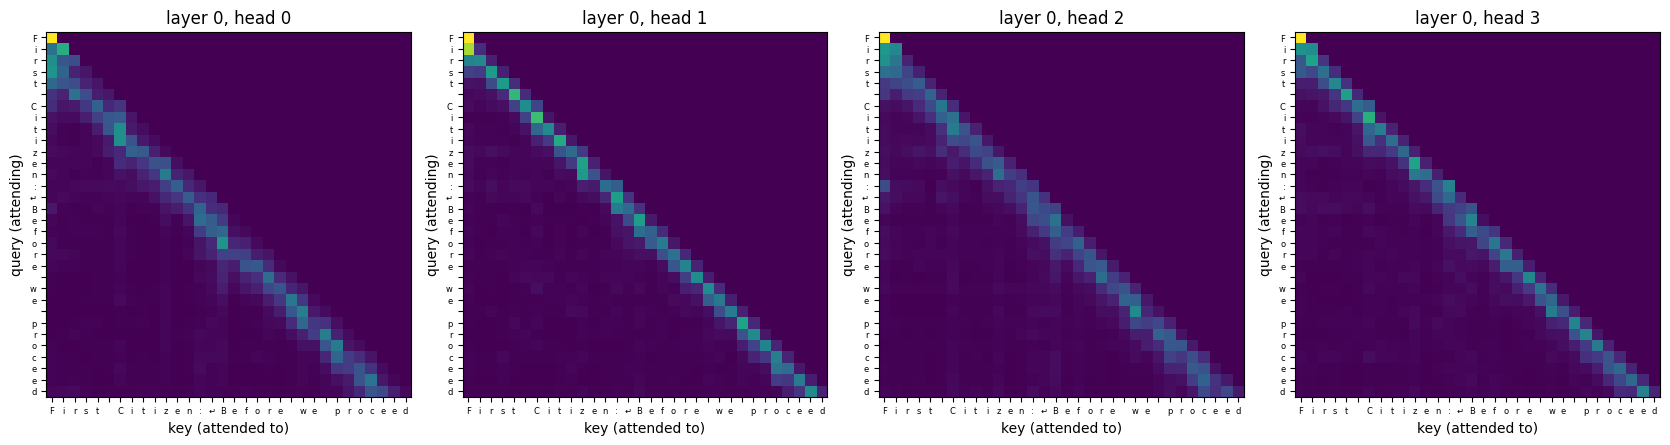

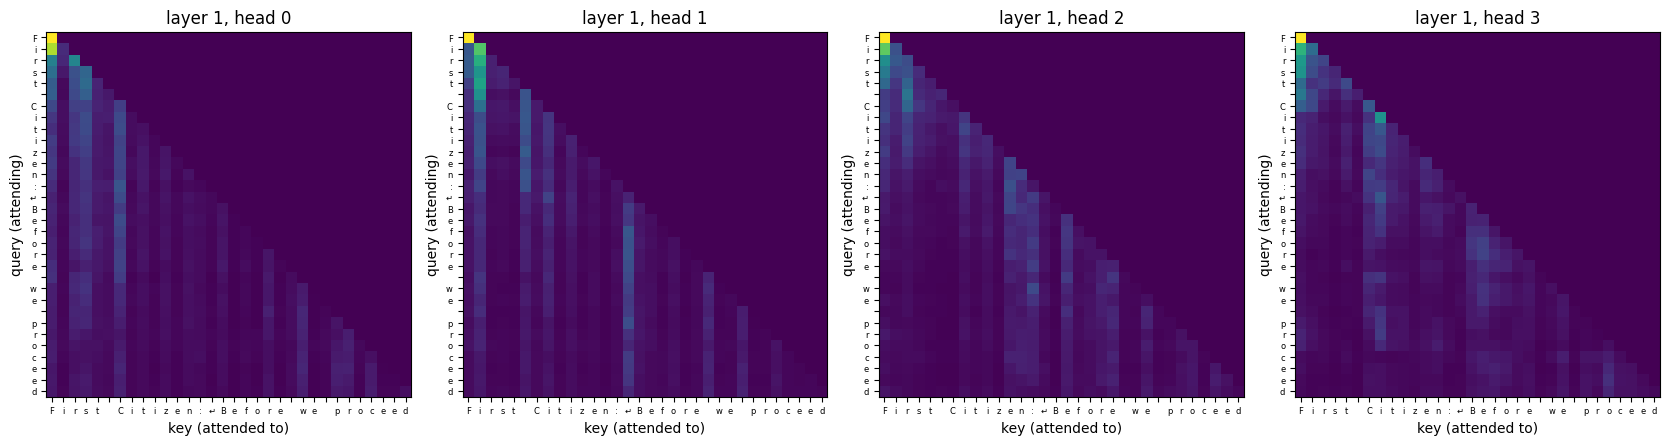

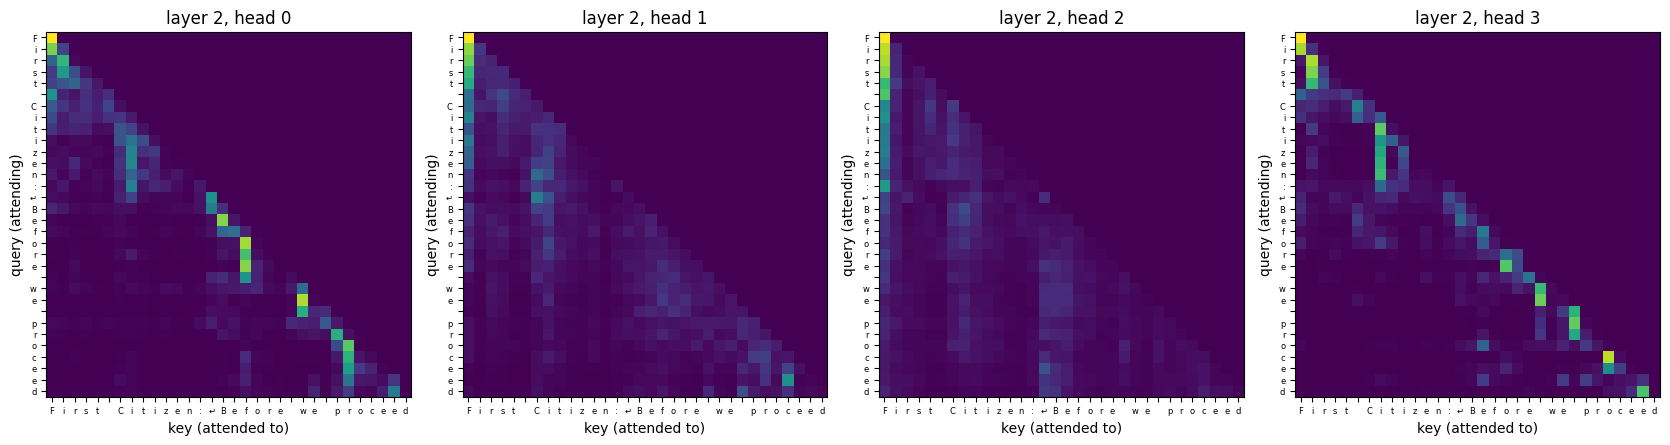

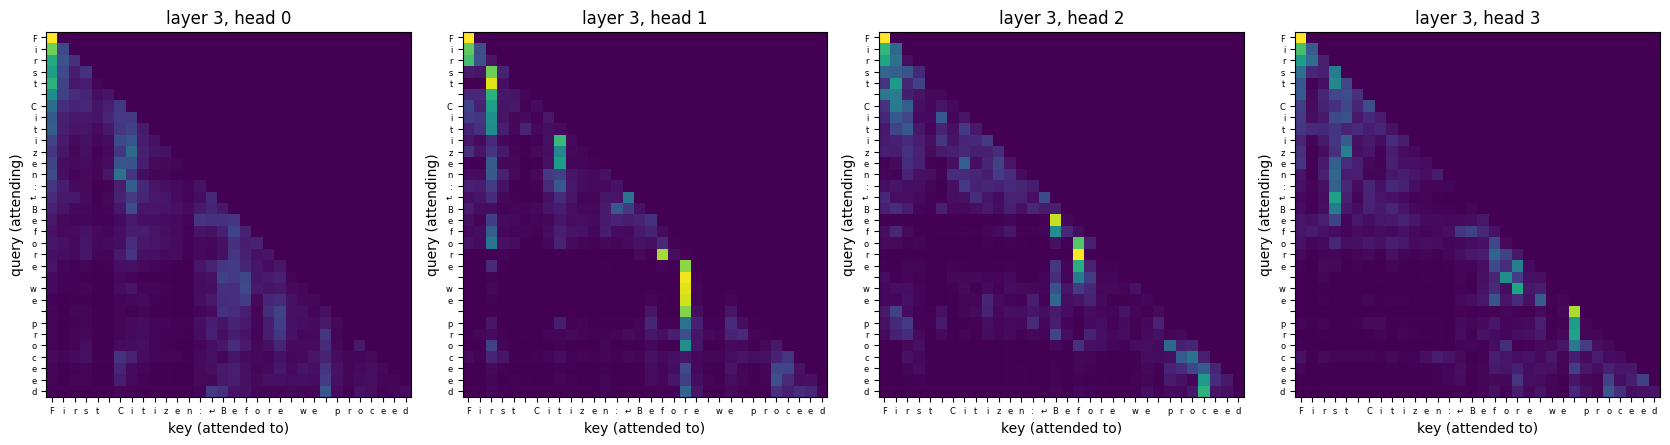

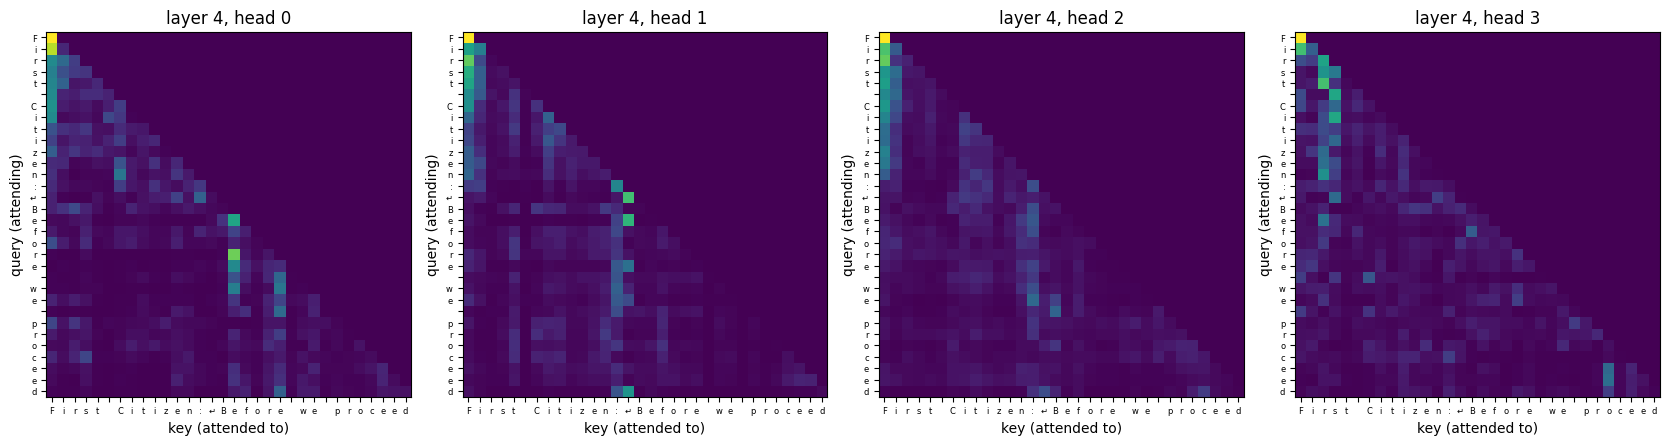

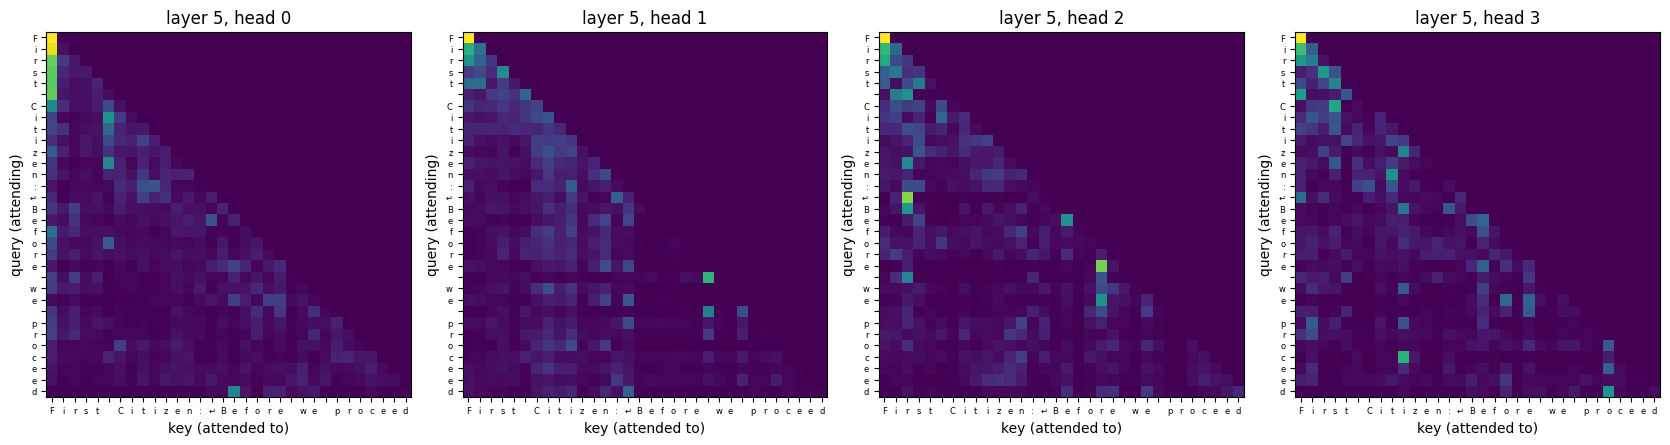

In [21]:
def show_attention(model, prompt, layer=0, max_heads=4):
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)[:, -block_size:]
    heads = model.blocks[layer].sa.heads
    for h in heads:
        h.keep_attn = True
    with torch.no_grad():
        model(ids)

    n = min(max_heads, len(heads))
    labels = [c if c != '\n' else '\u21b5' for c in decode(ids[0].tolist())]
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.4))
    axes = [axes] if n == 1 else axes
    for i, ax in enumerate(axes):
        ax.imshow(heads[i].last_wei[0].numpy(), cmap='viridis')
        ax.set_title(f'layer {layer}, head {i}')
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=6)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=6)
        ax.set_xlabel('key (attended to)'); ax.set_ylabel('query (attending)')
    plt.tight_layout(); plt.show()

    for h in heads:
        h.keep_attn = False
        h.last_wei = None
for n in range(n_layer):
    show_attention(model, "First Citizen:\nBefore we proceed", layer=n)

## 9. From this *toy* to ChatGPT

The model above is architecturally almost the same as GPT-2. What differs in modern assistants is mostly **scale and training pipeline**:

| | This notebook | Modern LLM |
|---|---|---|
| Parameters | ~0.8M-11M | billions to trillions |
| Tokenizer | characters (65) | subword BPE (~50k-250k tokens) |
| Training data | 1 MB | trillions of tokens |
| Context length | 128-256 | thousands to millions |
| Architecture tweaks | - | RoPE, grouped-query attention, RMSNorm, SwiGLU, mixture-of-experts, ... |
| Training stages | pre-training only | pre-training, then supervised fine-tuning, then preference optimisation / RLHF |


**A pre-trained model like ours is a *document completer*. Turning it into an *assistant* requires the additional post-training, fine-tuning and alignment stages.**

### References and related reading

* Andrej Karpathy, *Let's build GPT: from scratch, in code, spelled out* (YouTube), and the [nanoGPT](https://github.com/karpathy/nanoGPT) repository.
* Vaswani et al., *Attention Is All You Need* (2017): the original Transformer paper.
* Radford et al., *Language Models are Unsupervised Multitask Learners* (GPT-2, 2019).
* Brown et al., *Language Models are Few-Shot Learners* (GPT-3, NeurIPS 2020).

## 10. Lab Questions

### DESCRIPTION OF TASKS for LAB 5:



**Compare the bigram baseline and the GPT: report the final validation loss and perplexity of both, and discuss the train/validation curves (is there over-fitting?) and the differences in the generated text**

| Model | Final validation loss | Perplexity |
|---|---:|---:|
| Bigram | 2.48 | 12.00 |
| GPT | 1.57 | 4.80 |

The bigram training and validation losses stay close, so there is little sign of overfitting. GPT starts overfitting after about 2,500 steps: its training loss keeps falling, but its validation loss rises.

The bigram mostly produces broken words, such as `Wileranousel`. GPT produces clearer words, speaker names and dialogue, such as `And let him be proud.`, although it still makes grammar mistakes and often lacks meaning.


**Generate text with at least 3 different combinations of temperature and top-k, and describe how each of them affects the output.**

In the Section 7, we generate text using the prompt: `ROMEO:\n` and different combinations of `temperature` and `top-k`.

| Temperature | Top-k | What we observed |
|---:|---|---|
| 0.5 | None | More ordinary phrases, such as `I have spoke my life`, but still some mistakes. |
| 1.0 | None | More varied dialogue, but errors such as `hildren`. |
| 1.0 | 10 | Recognisable dialogue and repeated speaker names, but invented words such as `skites`. |
| 1.5 | None | More unusual and less readable text, with invented words such as `Judassars`. |

Lower temperature favours likely characters, making text more predictable and potentially repetitive.

Higher temperature adds variety but can produce more mistakes.

Top-k limits the choices to the k most likely next characters; it does not guarantee correct words.


**Plot the attention maps of the first and last layer for a prompt of your choice. Describe at least two patterns you observe and discuss what the attention maps can and cannot tell us about the model.**

We used `First Citizen:\nBefore we proceed`. Section 8 contains the plots: layer **0** is the first layer and layer **5** is the last.

- **First layer:** attention is mostly near the diagonal, meaning characters mainly attend to themselves and nearby earlier characters.
- **Last layer:** attention is more spread out, and the heads focus on different earlier positions. This shows that the model also uses more distant context.

The maps show which positions each head attends to. However, they do not fully explain a prediction or prove that the model understands the text, because other parts of the model also affect the output.
